# Get h5ad of *Drosophila melanogaster*

In [ ]:
%%bash

wget -O "./matrix/Dmel_AFCA.h5ad.gz" "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218661/suppl/GSE218661%5Fadata%5Fhead%5FS%5Fv1%2E0%2Eh5ad%2Egz"
gunzip "./matrix/Dmel_AFCA.h5ad.gz"

# Get Orthologs

In [ ]:
%%bash

cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Drosophila_melanogaster.tsv" "./orthologs/Apis_cerana__v__Drosophila_melanogaster.tsv"

In [4]:
import pandas as pd
Acer_vs_Dmel = pd.read_csv("./orthologs/Apis_cerana__v__Drosophila_melanogaster.tsv", sep="\t")
Acer_vs_Dmel

,Orthogroup,Apis_cerana,Drosophila_melanogaster
0,OG0000003,"LOC114577755, LOC133665739, LOC114576756, LOC1...","FBgn0036019, FBgn0035382, FBgn0037322, FBgn002..."
1,OG0000005,"LOC133667162, LOC107993392, LOC107993407, LOC1...","FBgn0028963, FBgn0032096, FBgn0026389"
2,OG0000006,"LOC108003159, LOC108004120, LOC108004124, LOC1...","FBgn0038034, FBgn0038037, FBgn0015038, FBgn001..."
3,OG0000007,"LOC108001575, LOC108002265, LOC108002282, LOC1...","FBgn0030204, FBgn0039582, FBgn0026386, FBgn003..."
4,OG0000008,"LOC108003496, LOC108003495","FBgn0053834, FBgn0053855, FBgn0053861, FBgn005..."
...,...,...,...
7587,OG0009913,LOC107994572,FBgn0286977
7588,OG0009955,LOC108002014,FBgn0033340
7589,OG0009979,LOC107998208,FBgn0262026
7590,OG0010220,LOC108001355,FBgn0287589


In [5]:
def get_121_orthologs(df, sp1, sp2):
    # 只考虑两列都不含逗号的“候选单基因”
    df = df[
        ~df[sp1].str.contains(",", na=False)
        & ~df[sp2].str.contains(",", na=False)
    ].copy()

    # 严格一对一：sp1 和 sp2 各自都不允许出现重复值
    df = df[
        ~df.duplicated(subset=[sp1], keep=False)
        & ~df.duplicated(subset=[sp2], keep=False)
    ]
    #! 注意！！如果不这样做，某列仍然可能同时存在多行相同基因（即未除尽的一对多）
    #! 并且千万不要用简单的 .drop_duplicates(sp1).drop_duplicates(sp2)，因为会保留 sp1/sp2 列第一次出现的行，正常情况下应该将一对多的行全部去掉
    return df.drop_duplicates().reset_index(drop=True)

In [8]:
Acer_vs_Dmel_121 = get_121_orthologs(Acer_vs_Dmel, "Apis_cerana", "Drosophila_melanogaster")
Acer_vs_Dmel_121.to_csv("./orthologs/Acer_vs_Dmel_121.tsv", sep="\t", index=False)

# Check .h5ad gene id/gene name

OrthoFinder results are based on the `gene_id` column in the GTF file; however, since `anndata.var.index` in `h5ad` files from different sources is not necessarily the `gene_id`, this issue is addressed here.

In [ ]:
%%bash
wget -O "./metadata/Drosophila_melanogaster.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/drosophila_melanogaster/Drosophila_melanogaster.BDGP6.54.63.gtf.gz"
gunzip "./metadata/Drosophila_melanogaster.gtf.gz"

In [ ]:
%%bash
gppy txinfo -g "./metadata/Drosophila_melanogaster.gtf" > "./metadata/Drosophila_melanogaster.tsv"

In [9]:
import pandas as pd

Dmel_gtf = pd.read_csv("./metadata/Drosophila_melanogaster.tsv", sep="\t")
Dmel_gtf

,tx_name,gene_id,chrom,strand,nexon,tx_len,cds_len,utr5_len,utr3_len,gene_biotype,gene_name,gene_source,protein_id,transcript_biotype,transcript_name,transcript_source,ensembl_canonical,seleno
0,FBti0060911-RA,FBti0060911,3R,+,1,41,0,0,0,transposable_element,transib2{}2850,FlyBase,NaN,transposable_element,NaN,FlyBase,True,False
1,FBtr0082878,FBgn0038189,3R,-,2,1101,1026,30,45,protein_coding,Art6,FlyBase,FBpp0082341,protein_coding,Art6-RA,FlyBase,True,False
2,FBtr0081853,FBgn0037583,3R,-,6,2146,1929,80,137,protein_coding,Veneno,FlyBase,FBpp0081342,protein_coding,Veneno-RA,FlyBase,True,False
3,FBtr0302308,FBgn0038606,3R,-,5,5262,2637,617,2008,protein_coding,CG15803,FlyBase,FBpp0291514,protein_coding,CG15803-RB,FlyBase,False,False
4,FBtr0345256,FBgn0038606,3R,-,4,4379,2643,617,1119,protein_coding,CG15803,FlyBase,FBpp0311433,protein_coding,CG15803-RC,FlyBase,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41585,FBtr0347034,FBgn0267595,211000022280341,-,1,740,0,0,0,pseudogene,CR45933,FlyBase,NaN,pseudogene,CR45933-RA,FlyBase,True,False
41586,FBtr0300161,FBgn0259864,211000022279392,-,1,1356,0,0,0,ncRNA,Su(Ste):CR42433,FlyBase,NaN,ncRNA,Su(Ste):CR42433-RA,FlyBase,True,False
41587,FBtr0302344,FBgn0085506,211000022278760,-,2,264,264,0,0,protein_coding,CG40635,FlyBase,FBpp0291548,protein_coding,CG40635-RB,FlyBase,True,False
41588,FBtr0300167,FBgn0259870,211000022279165,-,1,1105,0,0,0,ncRNA,Su(Ste):CR42439,FlyBase,NaN,ncRNA,Su(Ste):CR42439-RA,FlyBase,True,False


In [11]:
import scanpy as sc

Dmel = sc.read_h5ad("./matrix/Dmel_AFCA.h5ad")

In [12]:
Dmel_set = set(Dmel.var.index)

In [13]:
Dmel_121_set = set(Acer_vs_Dmel_121["Drosophila_melanogaster"].to_list())

In [14]:
Dmel_gid_set = set(Dmel_gtf["gene_id"].to_list())

目前已知，XXX_121_set 是特定物种与 *A. cerana* 一对一同源基因中，该物种基因的集合；XXX_set 是其他文章提供的表达矩阵中，该物种基因的集合；XXX_gid_set 是该物种 GTF 中，gene_id 列基因的集合。已知同源基因的计算是基于最新注释的，因此 XXX_121_set 一定是 XXX_gid_set 的子集。

但目前不确定的是 XXX_set，因为其对应的表达矩阵来自几年前的文章，不一定使用最新版的基因组注释。如果 XXX_set 不是 XXX_gid_set 的子集（或者说，XXX_set 中存在 XXX_gid_set 中没有的基因），可能会导致 XXX_121_set 与 XXX_set 的交集偏少，因此需核查 XXX_set 与 XXX_gid_set 的关系。

It is established that `XXX_121_set` represents the set of genes from a specific species involved in one-to-one orthologous pairs with *A. cerana*; `XXX_set` represents the set of genes from that species found in an expression matrix from a previous study; and `XXX_gid_set` represents the set of genes listed in the `gene_id` column of that species' GTF file. Since the orthologous gene identification was based on the latest annotation, `XXX_121_set` is necessarily a subset of `XXX_gid_set`.

However, the status of `XXX_set` is uncertain because the corresponding expression matrix originates from a study published several years ago and may not utilize the most recent genome annotation. If `XXX_set` is not a subset of `XXX_gid_set` (i.e., if `XXX_set` contains genes absent from `XXX_gid_set`), the intersection between `XXX_121_set` and `XXX_set` might be artificially low; therefore, the relationship between `XXX_set` and `XXX_gid_set` requires verification.

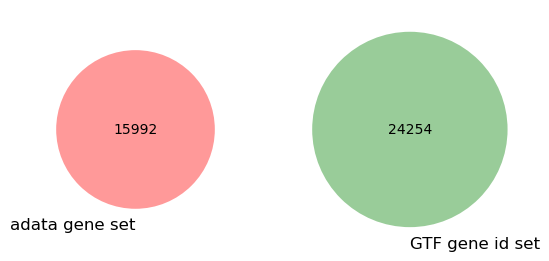

In [16]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt

v = venn2([Dmel_set, Dmel_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()
# It appears that the fruit fly adata.var.index uses the gene_name column from the GTF file rather than the gene_id column

*D. melanogaster*: 15992 genes of `adata gene set` not in `GTF gene id set`

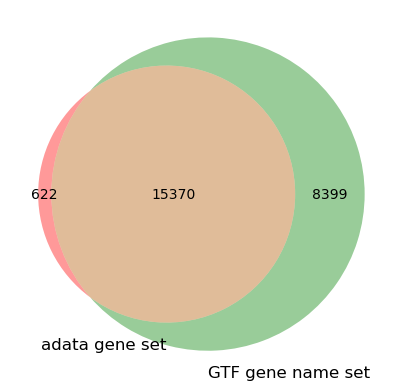

In [17]:
Dmel_gname_set = set(Dmel_gtf["gene_name"].to_list())
v = venn2([Dmel_set, Dmel_gname_set], set_labels=("adata gene set", "GTF gene name set"))
plt.show()

In [ ]:
%%bash

wget -O "./metadata/fb_synonym_fb_2021_06.tsv.gz" "https://s3ftp.flybase.org/releases/FB2021_06/precomputed_files/synonyms/fb_synonym_fb_2021_06.tsv.gz"
wget -O "./metadata/fb_synonym_fb_2026_03.tsv.gz" "https://s3ftp.flybase.org/releases/FB2026_03/precomputed_files/synonyms/fb_synonym_fb_2026_03.tsv.gz"
gunzip "./metadata/fb_synonym_fb_2021_06.tsv.gz"
gunzip "./metadata/fb_synonym_fb_2026_03.tsv.gz" 

In [23]:
Dmel_not_in_gtf = Dmel_set - Dmel_gname_set

In [25]:
fb_synonym_2021 = pd.read_csv("./metadata/fb_synonym_fb_2021_06.tsv", sep="\t", skiprows=5)
fb_synonym_2021


/tmp/ipykernel_66893/3196726714.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  fb_synonym_2021 = pd.read_csv("./metadata/fb_synonym_fb_2021_06.tsv", sep="\t", skiprows=5)


,##primary_FBid,organism_abbreviation,current_symbol,current_fullname,fullname_synonym(s),symbol_synonym(s)
0,FBtr0005088,Dmel,Pp2A-29B-RA,NaN,NaN,CG13383-RA|CG33297-RA
1,FBtr0006151,Dmel,Adhr-RA,NaN,NaN,Adhr-RC|CG32954-RC
2,FBtr0070000,Dmel,Nep3-RA,NaN,NaN,CG9565-RA
3,FBtr0070002,Dmel,CG9570-RA,NaN,NaN,NaN
4,FBtr0070003,Dmel,Or19b-RA,NaN,NaN,CG32825-RA
...,...,...,...,...,...,...
956092,FBab0049243,Dmel,Df(2R)9B4,NaN,NaN,Df9B4|Nup54[9B4]|Nup54[9B4]
956093,FBab0049244,Dmel,Df(3L)dpr6-10-L,NaN,NaN,dpr6-10[L]|dpr6-10[L]
956094,FBab0049245,Dmel,Df(2L)Dc,NaN,NaN,NaN
956095,FBab0049246,Dmel,Df(2R)chn[19E],NaN,NaN,NaN


In [32]:
fb_synonym_2026 = pd.read_csv("./metadata/fb_synonym_fb_2026_03.tsv", sep="\t", skiprows=5)
fb_synonym_2026

/tmp/ipykernel_66893/3231963107.py:1: DtypeWarning: Columns (3,4) have mixed types. Specify dtype option on import or set low_memory=False.
  fb_synonym_2026 = pd.read_csv("./metadata/fb_synonym_fb_2026_03.tsv", sep="\t", skiprows=5)


,##primary_FBid,organism_abbreviation,current_symbol,current_fullname,fullname_synonym(s),symbol_synonym(s)
0,FBba0000001,Dmel,CyO-Df(2R)B80,Curly of Oster-Df(2R)B80,NaN,NaN
1,FBba0000002,Dmel,FM3,First Multiple 3,NaN,NaN
2,FBba0000003,Dmel,FM6,First Multiple 6,NaN,NaN
3,FBba0000004,Dmel,FM6-12,NaN,NaN,NaN
4,FBba0000005,Dmel,CyO-numb[k09918],NaN,NaN,NaN
...,...,...,...,...,...,...
1020523,FBgn0290725,Dmel,piRNA:77B,NaN,cluster 77B,NaN
1020524,FBgn0290726,Hsap,Hsap\METTL1,"methyltransferase 1, tRNA methylguanosine",methyltransferase like 1,C12orf1|METTL1|TRM8|TRMT8
1020525,FBgn0290727,Hasp,Hasp\OR20,Odorant receptor 20,NaN,OR20
1020526,FBgn0290728,Dmel,fs(1)GS10,female sterile (1) GS10,NaN,NaN


In [40]:
import re
from collections import defaultdict
import pandas as pd

def load_flybase_synonyms(path):
    sym2fbgn = defaultdict(set)
    syn2fbgn = defaultdict(set)
    with open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            p = line.rstrip("\n").split("\t") # 原来是 rstrip("")，这里修正
            if len(p) < 6:
                continue
            fbid, org, csym, cfull, fsyn, ssyn = p[:6]

            if org != "Dmel" or not fbid.startswith("FBgn"):
                continue

            if csym.strip():
                sym2fbgn[csym.strip()].add(fbid)

            if ssyn:
                for s in ssyn.split("|"):
                    s = s.strip()
                    if s:
                        syn2fbgn[s].add(fbid)

    return sym2fbgn, syn2fbgn


sym21, syn21 = load_flybase_synonyms("./metadata/fb_synonym_fb_2021_06.tsv")
sym26, syn26 = load_flybase_synonyms("./metadata/fb_synonym_fb_2026_03.tsv")

def resolve(g):
    """只返回唯一 FBgn；多候选直接丢弃。"""
    g = str(g).strip()

    for source, table in [
        ("2021_current", sym21),
        ("2021_synonym", syn21),
        ("2026_current", sym26),
        ("2026_synonym", syn26),
    ]:
        hits = {
            h for h in table.get(g, set())
            if h.startswith("FBgn")
        }

        if len(hits) == 1:
            return next(iter(hits)), source

        if len(hits) > 1:
            return None, f"ambiguous:{source}:{len(hits)}"

    return None, "unresolved"

# ---------- 1. 映射 GTF 外的 622 个基因 ----------
records = []

for g in sorted(Dmel_not_in_gtf):
    fbgn, status = resolve(g)
    records.append((g, fbgn, status))

map_df = pd.DataFrame(
    records,
    columns=["gene_name", "gene_id", "status"],
)

print("映射状态：")
print(map_df.status.value_counts().to_string())

print("\n被丢弃的多候选/未解析基因：")
print(map_df[map_df.gene_id.isna()].to_string(index=False))

映射状态：
status
2021_current                315
2021_synonym                294
ambiguous:2021_synonym:2     10
2026_current                  3

被丢弃的多候选/未解析基因：
gene_name gene_id                   status
      312    None ambiguous:2021_synonym:2
     ABCD    None ambiguous:2021_synonym:2
  CG12163    None ambiguous:2021_synonym:2
  CG30456    None ambiguous:2021_synonym:2
   CG7339    None ambiguous:2021_synonym:2
     Dak1    None ambiguous:2021_synonym:2
   Gtp-bp    None ambiguous:2021_synonym:2
    Pex11    None ambiguous:2021_synonym:2
  RpII215    None ambiguous:2021_synonym:2
      tam    None ambiguous:2021_synonym:2


In [57]:
print((map_df[~map_df["gene_id"].isna()]).shape[0])
#! ↑ 匹配到 622 个基因中的 612 个 FBgn ID（唯一匹配）
# ↓ 确定 612 中没有重复基因：
print((map_df[~map_df["gene_id"].isna()]["gene_id"].value_counts() > 1).sum())

612
0


In [46]:
# ---------- 2. 合并 GTF 内映射 ----------
Dmel_in_gtf = Dmel_set & Dmel_gname_set

gtf_map = (
    Dmel_gtf[Dmel_gtf["gene_name"].isin(Dmel_in_gtf)]
    [["gene_name", "gene_id"]]
    .drop_duplicates()
)

syn_map = map_df.dropna(subset=["gene_id"])[["gene_name", "gene_id"]]

In [47]:
gtf_map

,gene_name,gene_id
1,Art6,FBgn0038189
3,CG15803,FBgn0038606
5,lncRNA:CR46035,FBgn0267702
6,side-III,FBgn0083949
7,CG5509,FBgn0038054
...,...,...
41582,Su(Ste):CR42418,FBgn0259849
41583,Mst77Y-16Psi,FBgn0085494
41586,Su(Ste):CR42433,FBgn0259864
41587,CG40635,FBgn0085506


In [48]:
syn_map

,gene_name,gene_id
0,26-29-p,FBgn0250848
2,A16,FBgn0028965
3,AANAT1,FBgn0287831
4,ABCA,FBgn0031170
6,ADPS,FBgn0033983
...,...,...
616,snoRNA:Psi28S-1936,FBgn0082993
617,snoRNA:Psi28S-2263,FBgn0082990
618,snoRNA:Psi28S-612,FBgn0082953
619,ste14,FBgn0036336


In [59]:
# 检查 612 和 15,370 中是否存在重复基因名称
gtf_syn_inter = set(gtf_map["gene_id"].to_list()) & set(syn_map["gene_id"].to_list())
gtf_map_exinter = gtf_map[~gtf_map["gene_id"].isin(gtf_syn_inter)]

Dmel_all_map_df = pd.concat(
    [gtf_map_exinter, syn_map],
    ignore_index=True,
)
Dmel_all_map_df

,gene_name,gene_id
0,Art6,FBgn0038189
1,CG15803,FBgn0038606
2,lncRNA:CR46035,FBgn0267702
3,side-III,FBgn0083949
4,CG5509,FBgn0038054
...,...,...
15973,snoRNA:Psi28S-1936,FBgn0082993
15974,snoRNA:Psi28S-2263,FBgn0082990
15975,snoRNA:Psi28S-612,FBgn0082953
15976,ste14,FBgn0036336


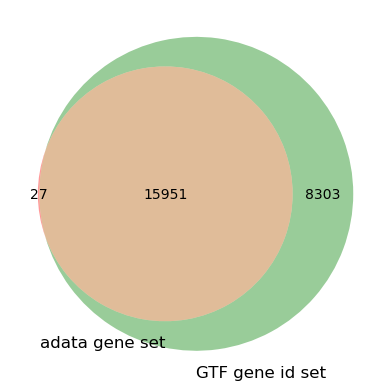

In [63]:
v = venn2([set(Dmel_all_map_df["gene_id"].to_list()), Dmel_gid_set], set_labels=("adata gene id set", "GTF gene id set"))
plt.show()

In [64]:
Dmel_all_map_df.to_csv("./metadata/Dmel_AFCA_all_gid.tsv", sep="\t",
    index=False,)

In [65]:
name_to_id = dict(
    zip(Dmel_all_map_df["gene_name"], Dmel_all_map_df["gene_id"])
)
Dmel.var["gene_id"] = Dmel.var_names.map(name_to_id)

# 没映射上的基因丢弃
Dmel = Dmel[:, Dmel.var["gene_id"].notna()].copy()

# 用 gene_id 作为新的 var_names
Dmel.var = Dmel.var.set_index("gene_id")
assert Dmel.var_names.is_unique

In [109]:
Dmel.var

""
gene_id
FBgn0010339
FBgn0020238
FBgn0004907
FBgn0010340
FBgn0085813
...
FBgn0052311
FBgn0024177
FBgn0261266


In [67]:
Dmel.write_h5ad("./matrix/Dmel_AFCA_FBgn.h5ad")

# Get gene list for MetaNeighbor

Not all genes in Acer_vs_XXX_121.tsv can be used in MetaNeighbor: 

Acer_vs_XXX_121 中部分基因可能出现在了原始表达矩阵中，但在质控过程中被过滤掉，因此没有出现在 XXX_set 中，而出现在 XXX_set 中的基因，很多又与 *A. cerana* 无直系同源关系，因此没有出现在 Acer_vs_XXX_121 中

Some genes from Acer_vs_XXX_121 may have been present in the initial expression matrix but were filtered out during quality control—and thus do not appear in XXX_set—whereas many genes found in XXX_set lack direct orthologs in *A. cerana* and therefore do not appear in Acer_vs_XXX_121.

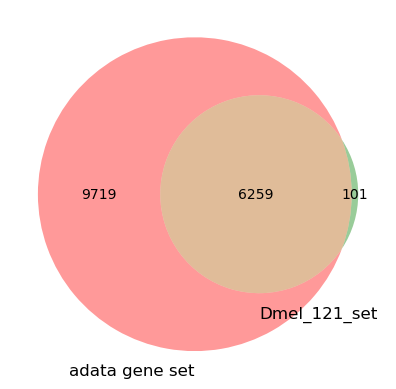

In [70]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt

v = venn2([set(Dmel_all_map_df["gene_id"].to_list()), Dmel_121_set], set_labels=("adata gene set", "Dmel_121_set"))
plt.show()

In [71]:
def get_121_for_mn(
        adata_gid_set: set, 
        ortho_121_set: set, 
        ortho_121_table: pd.DataFrame,
        sp_name: str
    ):
    inter = adata_gid_set & ortho_121_set
    sub_table = ortho_121_table[ortho_121_table[sp_name].isin(inter)]
    return sub_table

In [72]:
Acer_vs_Dmel_121_4mn = get_121_for_mn(set(Dmel_all_map_df["gene_id"].to_list()), Dmel_121_set, Acer_vs_Dmel_121, "Drosophila_melanogaster")
Acer_vs_Dmel_121_4mn.shape[0]

6259

In [76]:
Acer_vs_Dmel_121_4mn.to_csv("./orthologs/Acer_vs_Dmel_121_4mn(AFCA).tsv", sep="\t", index=False)

# Prepare .h5ad for MetaNeighbor (R) input:

In [77]:
Dmel

AnnData object with n_obs × n_vars = 289981 × 15978
    obs: 'tissue', 'sex', 'age', 'sex_age', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'log1p_total_counts_mt', 'dataset', 'fca_annotation', 'afca_annotation', 'afca_annotation_broad'
    uns: 'afca_annotation_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'

In [78]:
# 检查anndata
import numpy as np
import pandas as pd
import scipy.sparse as sp

In [100]:
# Dmel = sc.read_h5ad("./matrix/Dmel_AFCA_FBgn.h5ad")
Dmel_origin = sc.read_h5ad("./matrix/Dmel_AFCA.h5ad")
#! 因为后续发现X并非原始计数矩阵，如果对Dmel_AFCA_FBgn.h5ad进行恢复，由于Dmel_AFCA_FBgn.h5ad相对原矩阵删除了部分基因，会导致评判标准不准确
#! 因此，在这里读取Dmel_AFCA.h5ad，先恢复原始计数，然后对基因取子集

In [97]:
# =========================================================
# 0. 公共检查函数
# =========================================================
def check_matrix(adata, label="X"):
    X = adata.X
    if not sp.issparse(X):
        X = sp.csr_matrix(X)
    else:
        X = X.tocsr()

    d = X.data
    row_sums = np.asarray(X.sum(axis=1)).ravel()
    col_sums = np.asarray(X.sum(axis=0)).ravel()

    print(f"\n===== {label} =====")
    print("shape:", X.shape)
    print("dtype:", X.dtype)
    print("min / max:", d.min(), d.max())
    print("all finite:", np.isfinite(d).all())
    print("nonnegative:", (d >= 0).all())
    print("integer-valued:", np.allclose(d, np.round(d)))
    print("zero cells:", int((row_sums == 0).sum()))
    print("zero genes:", int((col_sums == 0).sum()))

    if "total_counts" in adata.obs:
        obs_total = adata.obs["total_counts"].values.astype(float)
        print("max |row_sum - total_counts|:",
              np.max(np.abs(row_sums - obs_total)))
        print("allclose:",
              np.allclose(row_sums, obs_total))

    print("var_names unique:", adata.var_names.is_unique)
    print("obs_names unique:", adata.obs_names.is_unique)
    return X, row_sums, col_sums

In [101]:
# =========================================================
# 1. 检查 Dmel.X
# =========================================================
X, row_sums, col_sums = check_matrix(Dmel_origin, "Dmel.X before conversion")

d = X.data
integer_valued = np.allclose(d, np.round(d))
nonnegative = (d >= 0).all()
total_counts = Dmel_origin.obs["total_counts"].values.astype(float)

already_counts = (
    integer_valued
    and nonnegative
    and np.allclose(row_sums, total_counts)
)

print("\nX already raw counts:", already_counts)


===== Dmel.X before conversion =====
shape: (289981, 15992)
dtype: float32
min / max: 0.4682032 8.615613
all finite: True
nonnegative: True
integer-valued: False
zero cells: 0
zero genes: 1310
max |row_sum - total_counts|: 13614.925048828125
allclose: False
var_names unique: True
obs_names unique: True

X already raw counts: False


↑ 这不是原始计数矩阵，需要转换

In [102]:
# =========================================================
# 2. 如果不是 raw counts，则从 log1p(CP10K) 还原
# =========================================================
if not already_counts:
    X_log = X.copy()

    # 检查是否是 log1p(CP10K)
    X_exp = X_log.copy()
    X_exp.data = np.expm1(X_exp.data)
    exp_sums = np.asarray(X_exp.sum(axis=1)).ravel()

    print("expm1 row sums: min / median / max =",
          exp_sums.min(), np.median(exp_sums), exp_sums.max())

    assert np.allclose(exp_sums, 1e4, rtol=1e-3), (
        "Dmel_origin.X 看起来不是 log1p(CP10K)，不能直接用 total_counts 还原"
    )

    # CP10K -> 原始 counts
    X_counts = X_exp.multiply(total_counts[:, None] / 1e4).tocsr()
    X_counts.data = np.rint(X_counts.data)
    X_counts.eliminate_zeros()

    Dmel_origin.X = X_counts.astype(np.float32)
    print("Dmel_origin.X has been reconstructed from log1p(CP10K).")

expm1 row sums: min / median / max = 9999.997 10000.0 10000.003
Dmel_origin.X has been reconstructed from log1p(CP10K).


In [104]:
# =========================================================
# 3. 转换后再次检查
# =========================================================
X, row_sums, col_sums = check_matrix(Dmel_origin, "Dmel_origin.X after conversion")

assert np.allclose(X.data, np.round(X.data)), "X 仍然不是整数 counts"
assert (X.data >= 0).all(), "X 存在负值"
assert np.allclose(row_sums, total_counts), "行和与 total_counts 不一致"
assert (row_sums > 0).all(), "存在全零细胞"


===== Dmel_origin.X after conversion =====
shape: (289981, 15992)
dtype: float32
min / max: 1.0 1619.0
all finite: True
nonnegative: True
integer-valued: True
zero cells: 0
zero genes: 1310
max |row_sum - total_counts|: 0.0
allclose: True
var_names unique: True
obs_names unique: True


In [106]:
Dmel_all_map_df = pd.read_csv("./metadata/Dmel_AFCA_all_gid.tsv", sep="\t",)

name_to_id = dict(
    zip(Dmel_all_map_df["gene_name"], Dmel_all_map_df["gene_id"])
)
Dmel_origin.var["gene_id"] = Dmel_origin.var_names.map(name_to_id)

# 没映射上的基因丢弃
Dmel_origin = Dmel_origin[:, Dmel_origin.var["gene_id"].notna()].copy()

# 用 gene_id 作为新的 var_names
Dmel_origin.var = Dmel_origin.var.set_index("gene_id")
assert Dmel_origin.var_names.is_unique

In [110]:
Dmel_origin.var

""
gene_id
FBgn0010339
FBgn0020238
FBgn0004907
FBgn0010340
FBgn0085813
...
FBgn0052311
FBgn0024177
FBgn0261266


In [111]:
# 仅保留 Amel & Acer一对一直系同源基因
ortho = pd.read_csv(
    "./orthologs/Acer_vs_Dmel_121_4mn(AFCA).tsv",
    sep="\t",
)
ortho_set = set(ortho["Drosophila_melanogaster"].astype(str))

expressed = np.asarray(Dmel_origin.X.sum(axis=0)).ravel() > 0
in_ortholog = Dmel_origin.var_names.isin(ortho_set)
gene_keep = expressed & in_ortholog

print("\nOrtholog genes in AFCA:", len(ortho_set))
print("Kept ortholog genes:", int(gene_keep.sum()))

Dmel_origin = Dmel_origin[:, gene_keep].copy()

assert Dmel_origin.var_names.is_unique
assert Dmel_origin.var_names.isin(ortho_set).all()


Ortholog genes in AFCA: 6259
Kept ortholog genes: 6224


In [115]:
print(expressed.sum())
print(in_ortholog.sum())
print((expressed & in_ortholog).sum())
print(gene_keep.sum())

14667
6258
6224
6224


In [113]:
# =========================================================
# 7. 清理 obs 和多余 slot
# =========================================================
# fca_annotation 里含大量字面量 "nan"，不要作为 R 的 cell type 列
for col in ["afca_annotation", "afca_annotation_broad"]:
    if col in Dmel_origin.obs:
        s = (
            Dmel_origin.obs[col]
            .astype(str)
            .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
            .str.strip("_")
        )
        Dmel_origin.obs[col] = pd.Categorical(s)

keep_obs = [
    c for c in [
        "afca_annotation",
        "afca_annotation_broad",
        "dataset",
        "tissue",
        "sex",
        "age",
        "total_counts",
    ]
    if c in Dmel_origin.obs
]
Dmel_origin.obs = Dmel_origin.obs[keep_obs].copy()

In [114]:
# =========================================================
# 8. 最终检查
# =========================================================
X = Dmel_origin.X.tocsr()
row_sums = np.asarray(X.sum(axis=1)).ravel()
col_sums = np.asarray(X.sum(axis=0)).ravel()
d = X.data

print("\n===== Final Dmel_origin =====")
print("shape:", Dmel_origin.shape)
print("min / max:", d.min(), d.max())
print("all finite:", np.isfinite(d).all())
print("nonnegative:", (d >= 0).all())
print("integer-valued:", np.allclose(d, np.round(d)))
print("zero cells:", int((row_sums == 0).sum()))
print("zero genes:", int((col_sums == 0).sum()))
print("var_names unique:", Dmel_origin.var_names.is_unique)
print("obs_names unique:", Dmel_origin.obs_names.is_unique)
print("all var in ortholog:", Dmel_origin.var_names.isin(ortho_set).all())

assert Dmel_origin.var_names.is_unique
assert Dmel_origin.obs_names.is_unique
assert Dmel_origin.var_names.isin(ortho_set).all()
assert np.allclose(d, np.round(d))
assert (d >= 0).all()
assert (row_sums > 0).all()



===== Final Dmel_origin =====
shape: (289981, 6224)
min / max: 1.0 941.0
all finite: True
nonnegative: True
integer-valued: True
zero cells: 0
zero genes: 0
var_names unique: True
obs_names unique: True
all var in ortholog: True


In [117]:
Dmel_origin.layers = {}
Dmel_origin.obsm = {}
Dmel_origin.varm = {}
Dmel_origin.obsp = {}
Dmel_origin.uns = {}
Dmel_origin.raw = None

In [118]:
Dmel_origin

AnnData object with n_obs × n_vars = 289981 × 6224
    obs: 'afca_annotation', 'afca_annotation_broad', 'dataset', 'tissue', 'sex', 'age', 'total_counts'

In [120]:
Dmel_origin.write_h5ad("./matrix/Dmel_AFCA_FBgn_4_metaNeignboR.h5ad")

# Prepare .h5ad for MetaNeighbor (R) input (*Apis cerana*):

In [129]:
Acer = sc.read_h5ad("./matrix/01_Acer_transfromHY.h5ad")
Acer

AnnData object with n_obs × n_vars = 58166 × 11817
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'batch', 'leiden_res0.25', 'leiden_res0.50', 'leiden_res1.00', 'HY_barcode', 'celltype_transfrom_HY'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'batch_colors', 'celltype_transfrom_HY_colors', 'hvg', 'leiden_res0.25', 'leiden_res0.25_colors', 'leiden_res0.50', 'leiden_res0.50_colors', 'leiden_res1.00', 'leiden_res1.00_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'logcounts'
    obsp: 'connectivities', 'distances'

In [131]:
(Acer.var.index != Acer.var["gene_ids"]).sum()

np.int64(0)

In [123]:
X_counts = Acer.layers["counts"].tocsr().copy()

# 值都是整数，float32 足够，且能减小文件体积
Acer.X = X_counts.astype(np.float32)

# 删除 logcounts，避免后续误用
Acer.layers = {}

# =========================================================
# 3. 检查 counts
# =========================================================
X = Acer.X.tocsr()
d = X.data
row_sums = np.asarray(X.sum(axis=1)).ravel()
col_sums = np.asarray(X.sum(axis=0)).ravel()

print("===== Acer counts check =====")
print("shape:", X.shape)
print("dtype:", X.dtype)
print("min / max:", d.min(), d.max())
print("all finite:", np.isfinite(d).all())
print("nonnegative:", (d >= 0).all())
print("integer-valued:", np.allclose(d, np.round(d)))
print("zero cells:", int((row_sums == 0).sum()))
print("zero genes:", int((col_sums == 0).sum()))
print("var_names unique:", Acer.var_names.is_unique)
print("obs_names unique:", Acer.obs_names.is_unique)

if "total_counts" in Acer.obs:
    obs_total = Acer.obs["total_counts"].values.astype(float)
    diff = np.abs(row_sums - obs_total)
    print("max |row_sum - total_counts|:", diff.max())
    print("max relative diff:", np.max(diff / obs_total))

assert d.min() >= 0
assert np.allclose(d, np.round(d))
assert (row_sums > 0).all()
assert Acer.var_names.is_unique
assert Acer.obs_names.is_unique

===== Acer counts check =====
shape: (58166, 11817)
dtype: float32
min / max: 1.0 7713.0
all finite: True
nonnegative: True
integer-valued: True
zero cells: 0
zero genes: 0
var_names unique: True
obs_names unique: True
max |row_sum - total_counts|: 21.0
max relative diff: 0.009825327510917031


In [124]:
# =========================================================
# 4. 标签处理
# =========================================================
label_cols = [
    "leiden_res0.25",
    "leiden_res0.50",
    "leiden_res1.00",
]

for col in label_cols:
    assert col in Acer.obs, f"缺少标签列: {col}"
    assert Acer.obs[col].notna().all(), f"{col} 存在 NaN"

    s = (
        Acer.obs[col]
        .astype(str)
        .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    Acer.obs[col] = pd.Categorical(s)

In [125]:
# =========================================================
# 5. 只保留需要的 obs 列
# =========================================================
# 不保留 celltype_transfrom_HY：
# 其中大量 unknown/UK，不适合作为正式 MetaNeighbor 标签。
keep_obs = [
    "leiden_res0.25",
    "leiden_res0.50",
    "leiden_res1.00",
    "batch",
    "HY_barcode",   # 可选；不想要可以删掉
]

keep_obs = [c for c in keep_obs if c in Acer.obs]
Acer.obs = Acer.obs[keep_obs].copy()

# =========================================================
# 6. 清理其它无用内容
# =========================================================
# 删除 var 中的 HVG、gene_ids、feature_types 等冗余列
Acer.var = Acer.var[[]].copy()

Acer.obsm = {}
Acer.varm = {}
Acer.obsp = {}
Acer.uns = {}
Acer.raw = None

# =========================================================
# 7. 最终检查
# =========================================================
X = Acer.X.tocsr()
d = X.data
row_sums = np.asarray(X.sum(axis=1)).ravel()
col_sums = np.asarray(X.sum(axis=0)).ravel()

print("\n===== Final Acer =====")
print("shape:", Acer.shape)
print("min / max:", d.min(), d.max())
print("integer-valued:", np.allclose(d, np.round(d)))
print("zero cells:", int((row_sums == 0).sum()))
print("zero genes:", int((col_sums == 0).sum()))
print("obs columns:", Acer.obs.columns.tolist())
print("var_names unique:", Acer.var_names.is_unique)
print("obs_names unique:", Acer.obs_names.is_unique)

assert Acer.var_names.is_unique
assert Acer.obs_names.is_unique
assert np.allclose(d, np.round(d))
assert (d >= 0).all()
assert (row_sums > 0).all()
assert all(c in Acer.obs for c in label_cols)



===== Final Acer =====
shape: (58166, 11817)
min / max: 1.0 7713.0
integer-valued: True
zero cells: 0
zero genes: 0
obs columns: ['leiden_res0.25', 'leiden_res0.50', 'leiden_res1.00', 'batch', 'HY_barcode']
var_names unique: True
obs_names unique: True


In [128]:
Acer.var

""
LOC107992807
LOC107992805
LOC107992806
LOC107992868
LOC107992792
...
KEH14_p05
KEH14_p04
KEH14_p03
KEH14_p02


In [ ]:
Acer.write_h5ad("./matrix/Acer_4_MetaNeighboR.h5ad")